Import the modules that will be used.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

## Exercise 11.1

Determine by counting the number of mathematical operations the complexity of:

1. Dot product between two vectors
1. Matrix-vector product
1. Matrix-matrix product

for vectors of length $n$ and matrices of size $n \times n$.

This is a reasoning exercise - you do not need to write a program. Express your answers in text and using LaTeX in a Markdown cell.


### Optional

Test the complexity experimentally with your own functions for performing the operations, and
with the NumPy 'vectorised' equivalents.

#### Dot product

Let $\mathbf{u} $ and $\mathbf{v} $ be two vectors of length $n$. The dot product is

$$
\mathbf{u} \cdot \mathbf{v} = \sum_{1}^{n} u_iv_i
$$

Involves $n$ multiplication and $n-1$ addition, a total of $2n-1$ operations, so time complexity is $O(2n-1)=O(n)$

#### Matrix-vector product

Let $\mathbf{A}$ be a matrix of size $n \times n$ and $\mathbf{x}$ be a vector of length $n$. The matrix-vector product is

$$
y_i = \sum_{j=1}^{n} A_{ij}x_j \quad \text{for } i = 1, \dots, n
$$

For each of the $n$ rows, it involves $n$ multiplications and $n-1$ additions. A total of $n \times (2n-1) = 2n^2-n$ operations, so time complexity is $O(2n^2-n)=O(n^2)$

#### Matrix-matrix product

Let $\mathbf{A}$ and $\mathbf{B}$ be two matrices of size $n \times n$. The matrix-matrix product is

$$
C_{ij} = \sum_{k=1}^{n} A_{ik}B_{kj} \quad \text{for } i,j = 1, \dots, n
$$

The result matrix $\mathbf{C}$ has $n^2$ elements. Computing each element involves a dot product of length $n$ ($2n-1$ operations). A total of $n^2 \times (2n-1) = 2n^3-n^2$ operations, so time complexity is $O(2n^3-n^2)=O(n^3)$

## Exercise 11.2

For the recursive factorial algorithm in Activity 04, determine the algorithmic complexity by inspecting your implementation of the algorithm. Test this against numerical experiments.

### Solution

Recall the factorial algorithm from Activity 04.4:

In [15]:
def factorial(n):
    if n == 0:
        return 1
    else:
        return factorial(n - 1)*n

The function calls itself (recursively) $n$ times, hence it has complexity $O(n)$. We test this below and plot
the times.

/tmp/ipykernel_3544/1108553842.py:5: RuntimeWarning: overflow encountered in scalar multiply
  return factorial(n - 1)*n


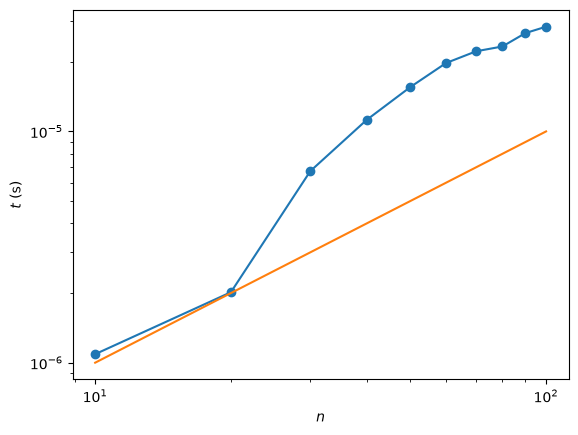

In [29]:
N = np.arange(10, 101, 10) 
times = []
for n in N:
    t = %timeit -q -o -n3 -r3 factorial(n)
    times.append(t.best)

plt.loglog(N, times, marker='o')
# Show a reference line of O(n)
plt.loglog(N, 1e-7*N, label='$O(n)$')
plt.xlabel('$n$')
plt.ylabel('$t$ (s)')
plt.show()

## Exercise 11.3

Determine experimentally the complexity of computing the determinant of a matrix. You can generate an $n \times n$ matrix using:

In [11]:
n = 100
A = np.random.rand(n, n)

and the determinant can be computed by:

In [5]:
det = np.linalg.slogdet(A)

Be sure that you test for sufficiently large $n$ to get into the 'large' $n$ regime.

### Solution

Time computation of determinant:

In [26]:
# Create array of problem sizes we want to test (powers of 2)
N = 2**np.arange(2, 12)
times = []
for n in N:
    A = np.random.rand(n, n)
    t = %timeit -q -o -n3 -r3 np.linalg.slogdet(A)
    times.append(t.best)

Plot result:

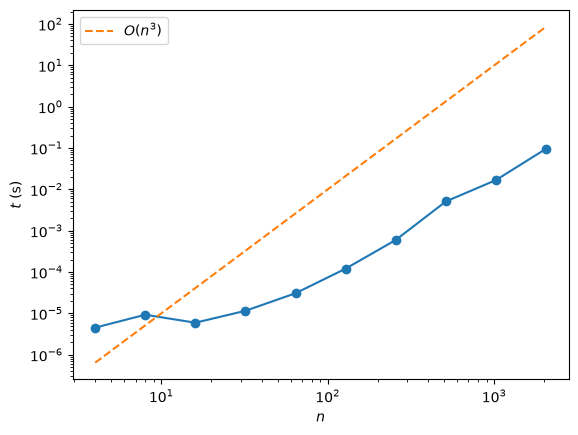

In [27]:
plt.loglog(N, times, marker='o')
plt.loglog(N, 1e-8*N**3, '--', label='$O(n^3)$')
plt.xlabel('$n$')
plt.ylabel('$t$ (s)')
plt.legend(loc=0)
plt.show()